# Assignment 1



## Question 1:
{method, implementation, answer}

Examine the value of sparse matricies by comparing the approximate computational efficiencies of sparse and dense solvers (on the same system). Use the %timeit function to approximate the complexity.

HINT: Refer to the lecture notes on how to generate, store, and apply sparse solvers.  

Method:
To compare the computational efficiency of sparse and dense solvers, I build the same tridiagonal linear The sparse matrix has mainly zero entries which allows the sparse solver to store and operate only on the non-zero elements.The computational times of the 2 approaches were compared using %timeit.

In [8]:
#Implementation#
import numpy as np
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve
# Size of the system
n = 1000

# Construct the tridiagonal matrix in sparse format
A_sparse = diags(
    [-np.ones(n-1), 2*np.ones(n), -np.ones(n-1)],
    [-1, 0, 1],
    format='csr'
)

# Right-hand side
b = np.ones(n)
# Convert the same matrix to dense format
A_dense = A_sparse.toarray()

#Dense solver
%timeit np.linalg.solve(A_dense, b)
#Sparse solver
%timeit spsolve(A_sparse, b)

x_dense = np.linalg.solve(A_dense, b)
x_sparse = spsolve(A_sparse, b)
np.allclose(x_dense, x_sparse)

39 ms ± 6.99 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
391 µs ± 12.3 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


True

Answer

The sparse solver is computationally more efficient for this system than the dense solver. Both solvers solve the same linear system and produce equivalent results, as confirmed by np.allclose().

The difference in efficiency happens because the matrix is sparse and most of its entries are zero. The dense solver stores and processes all entries of the matrix which is including the zeros, while the sparse solver primarily operates on the non-zero elements.

Therefore, sparse matrices can provide significant computational savings for both storage and computation when solving large systems that contain mostly zero entries. The %timeit results show us this difference in computational efficiency.

## Question 2

Consider the truss:

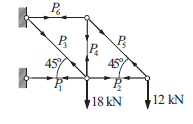


### 2a) Write the linear system for the tensions $P_i$ as equations and in matrix form
{answer}

Using equilibrium at the three free joints, with tension  as positive:

∑Fx =0,∑Fy=0

6 equations we get:
$$
\begin{aligned}
-P_1 + P_2 - \frac{P_3}{\sqrt{2}} &= 0 \\
\frac{P_3}{\sqrt{2}} + P_4 &= 18 \\
-P_4 - \frac{P_5}{\sqrt{2}} &= 0 \\
-P_6 + \frac{P_5}{\sqrt{2}} &= 0 \\
-P_2 - \frac{P_5}{\sqrt{2}} &= 0 \\
\frac{P_5}{\sqrt{2}} &= 12
\end{aligned}
$$


$$
\begin{bmatrix}
-1 & 1 & -1/\sqrt{2} & 0 & 0 & 0 \\
0 & 0 & 1/\sqrt{2} & 1 & 0 & 0 \\
0 & 0 & 0 & -1 & -1/\sqrt{2} & 0 \\
0 & 0 & 0 & 0 & 1/\sqrt{2} & -1 \\
0 & -1 & 0 & 0 & -1/\sqrt{2} & 0 \\
0 & 0 & 0 & 0 & 1/\sqrt{2} & 0
\end{bmatrix}
\begin{bmatrix}
P_1 \\
P_2 \\
P_3 \\
P_4 \\
P_5 \\
P_6
\end{bmatrix}
=
\begin{bmatrix}
0 \\
18 \\
0 \\
0 \\
0 \\
12
\end{bmatrix}
$$




### 2b) Solve for $P_i$ using LU decomposition and substitution.
{method, answer}

Method: Factor \(A=LU\), then solve \(Ly=b\) by forward substitution and \(Ux=y\) by back substitution.

In [9]:
import numpy as np
from scipy.linalg import lu

A = np.array([
    [-1, 1, -1/np.sqrt(2), 0, 0, 0],
    [0, 0, 1/np.sqrt(2), 1, 0, 0],
    [0, 0, 0, -1, -1/np.sqrt(2), 0],
    [0, 0, 0, 0, 1/np.sqrt(2), -1],
    [0, -1, 0, 0, -1/np.sqrt(2), 0],
    [0, 0, 0, 0, 1/np.sqrt(2), 0]
], dtype=float)

b = np.array([0, 18, 0, 0, 0, 12], dtype=float)

# LU decomposition
P, L, U = lu(A)

# Forward substitution: Ly = Pb
y = np.linalg.solve(L, P @ b)

# Back substitution: Ux = y
Pi = np.linalg.solve(U, y)

print("P1 =", Pi[0], "kN")
print("P2 =", Pi[1], "kN")
print("P3 =", Pi[2], "kN")
print("P4 =", Pi[3], "kN")
print("P5 =", Pi[4], "kN")
print("P6 =", Pi[5], "kN")

P1 = -24.0 kN
P2 = -12.0 kN
P3 = 16.970562748477143 kN
P4 = -12.0 kN
P5 = 16.970562748477143 kN
P6 = -6.0 kN


Final Answer:
P1 = -24.0 kN
P2 = -12.0 kN
P3 = 16.97 kN
P4 = -12.0 kN
P5 = 16.97 kN
P6 = -6.0 kN

The negative answers mean compression instead of tension.

### 2c)  Double the loads (18 kN and 12 kN) and solve for $P_i$ again *without refactoring*.
{answer}

In [10]:
# Double the loads
b2 = 2 * b

# Reuse the same L and U from 2b
y2 = np.linalg.solve(L, P @ b2)
Pi2 = np.linalg.solve(U, y2)

print("P1 =", Pi2[0], "kN")
print("P2 =", Pi2[1], "kN")
print("P3 =", Pi2[2], "kN")
print("P4 =", Pi2[3], "kN")
print("P5 =", Pi2[4], "kN")
print("P6 =", Pi2[5], "kN")

P1 = -48.0 kN
P2 = -24.0 kN
P3 = 33.941125496954285 kN
P4 = -24.0 kN
P5 = 33.941125496954285 kN
P6 = -12.0 kN


Final Answer:

P1 = -48.0 kN
P2 = -24.0 kN
P3 = 33.94 kN
P4 = -24.0 kN
P5 = 33.94 kN
P6 = -12.0 kN

Because the system is linear, doubling the loads doubles every member force and The LU factorization does not need to be repeated because \(A\) is unchanged.

## Question 3

Consider the matrix:

$$ A = \begin{bmatrix} 1 & 2 \\ 3 & 4 \end{bmatrix}$$

## 3a) Calculate the condition number of A
{answer}

In [11]:
import numpy as np

A = np.array([
    [1, 3],
    [2, 4]
], dtype=float)

condition_number = np.linalg.cond(A)

print(condition_number)


14.933034373659265


Final Answer: usimg the 2-norm,
k(A) = 14.93

## 3b) Let's use a preconditioner matrix $P$ to improve the condition number of the product $P^{-1} A$. Give 2 examples of $P$ that improve the condition number.

Can you identify the 'perfect' preconditioner? (Consider the easiest matrix to solve!)
{answer, answer}

In [12]:
P1 = np.array([
    [1, 0],
    [1, 1]
], dtype=float)

cond_P1A = np.linalg.cond(np.linalg.solve(P1, A))

print(cond_P1A)

5.828427124746187


$$
P_1 =
\begin{bmatrix}
1 & 0 \\
1 & 1
\end{bmatrix}
$$

$$
P_1^{-1}A =
\begin{bmatrix}
1 & 3 \\
1 & 1
\end{bmatrix}
$$

$$
\kappa(P_1^{-1}A) \approx 5.83
$$
-> smaller than 14.93

$$
P_2 =
\begin{bmatrix}
1 & 3 \\
2 & 4
\end{bmatrix}
$$

$$
P_2^{-1}A =
\begin{bmatrix}
1 & 0 \\
0 & 1
\end{bmatrix}
$$

A second example is the perfect preconditioner:$$
P_2 =A =
\begin{bmatrix}
1 & 3 \\
2 & 4
\end{bmatrix}
$$
and its condition number is
$$
\kappa(P_2^{-1}A)=\kappa(I)=1
$$

The perfect preconditioner is P=A, because it transforms the matrix into the identity matrix, which is the easiest matrix to solve and has the minimum possible condition number of 1.

